# Embolism detection in Doppler ultrasound signals

Exploratory pipeline that flags candidate embolic events in a stereo Doppler ultrasound recording. See the repository README for scope and limitations.

## Introduction

Embolic events appear in Doppler signals as short, high-intensity transients on top of background noise. This notebook builds a short-time energy trace of the recording, estimates and removes the slow background, and detects transients with several peak-detection strategies: a fixed threshold, the distance to a negative envelope, repeated noisy detections, and artefact rejection.

## Contents

1. Signal display
2. Frequency representation and spectrogram
3. Short-time energy
4. Background estimation (low-pass filtering)
5. Outlier removal (optional)
6. Detection with a fixed threshold
7. Negative envelope
8. Detection from the distance to the envelope
9. Repeated detection with added noise
10. Artefact detection
11. Percentile-based peak detection
12. Selection of relevant peaks
13. Rejection of events that coincide with artefacts

## Libraries

In [1]:
# NumPy: numerical computing and array manipulation.
import numpy as np

# SciPy: WAV file input/output.
import scipy.io.wavfile as wav

# Matplotlib: plotting.
import matplotlib.pyplot as plt

# Spectrogram computation.
from scipy.signal import spectrogram

# Kaiser window.
from scipy.signal.windows import kaiser

# Hamming window.
from scipy.signal.windows import hamming

# Digital filter design and application.
from scipy.signal import butter, filtfilt

# Peak detection.
from scipy.signal import find_peaks

# Hilbert transform.
from scipy.signal import hilbert

# Interpolation.
from scipy.interpolate import interp1d

## 1. Signal display

The stereo WAV file is loaded and its two channels are combined into a complex signal (`left - j * right`). A 10 s segment is selected (`ED = 10`; segment index `k`, where `k = 1` is 0-10 s) and its real and imaginary parts are plotted.

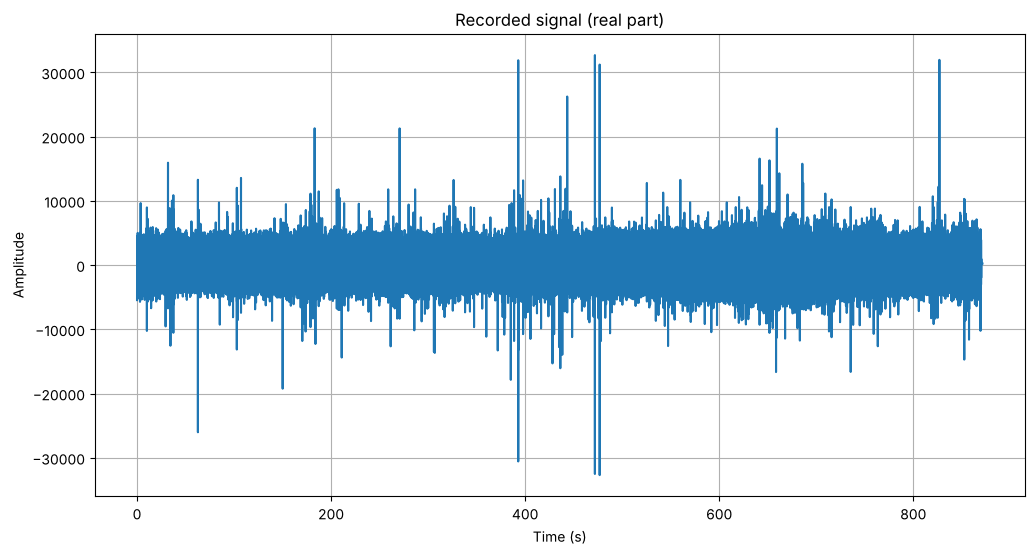

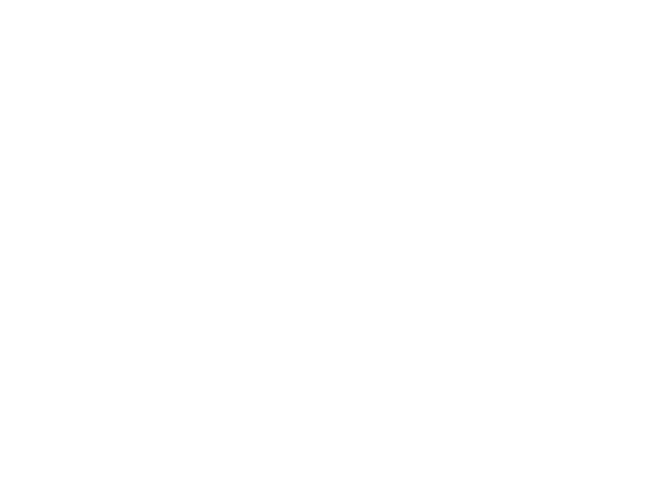

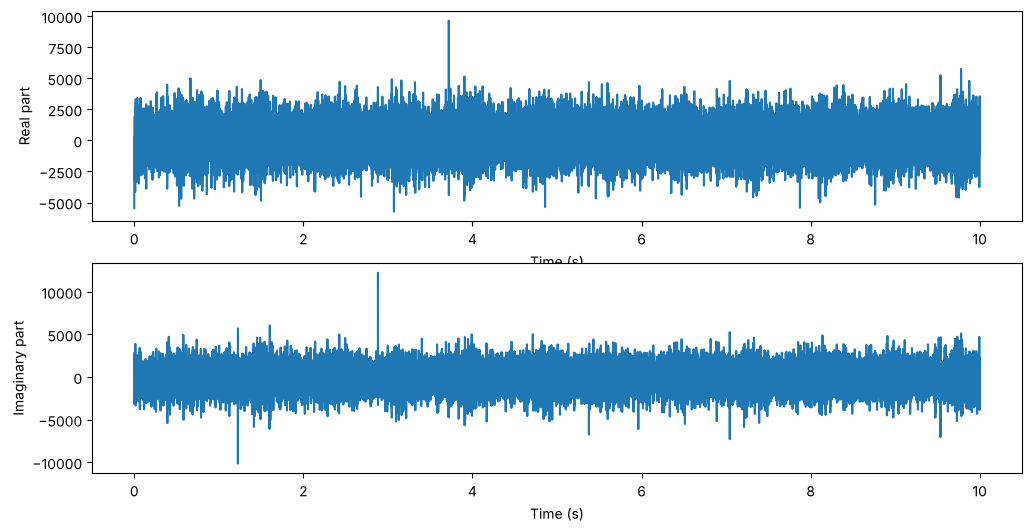

In [2]:
filename = '../data/T54_a.wav'
Fs, y = wav.read(filename)
X = y[:, 0] - 1j * y[:, 1]
Nmax = len(X)
TotalDuration = Nmax / Fs

# Plot the signal
plt.figure(figsize=(12, 6))
plt.plot(np.linspace(0, TotalDuration, Nmax), X.real)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title('Recorded signal (real part)')
plt.grid(True)
plt.show()

Overlap = 80 / 100
Lwind = 64
Delay = round(Lwind - (Lwind * Overlap))
ED = 10  # Frame duration
NObs = int(ED * Fs)
k = 1 # Segment index: 1 = [0, 10] s, 2 = [10, 20] s, etc.
x = X[(k - 1) * NObs:k * NObs]
tx = np.linspace(0, ED, len(x))



plt.figure()
plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)
plt.plot(tx, np.real(x))
plt.ylabel('Real part')
plt.xlabel('Time (s)')

plt.subplot(2, 1, 2)
plt.plot(tx, np.imag(x))
plt.ylabel('Imaginary part')
plt.xlabel('Time (s)')

plt.show()


## 2. Frequency representation and spectrogram

Magnitude spectrum of the segment (positive and negative frequencies shown separately) and its spectrogram.

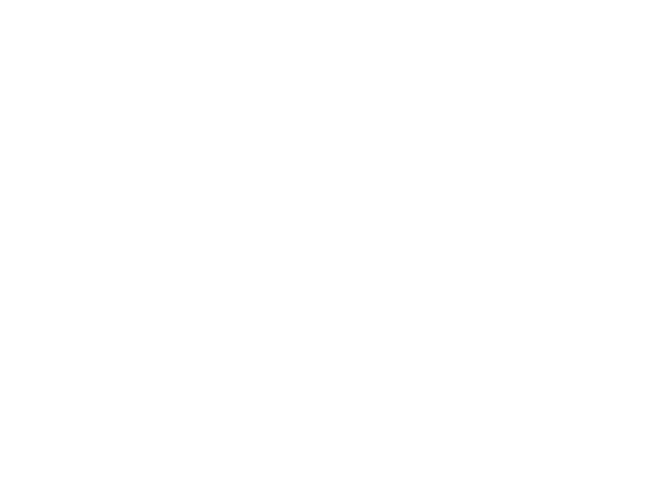

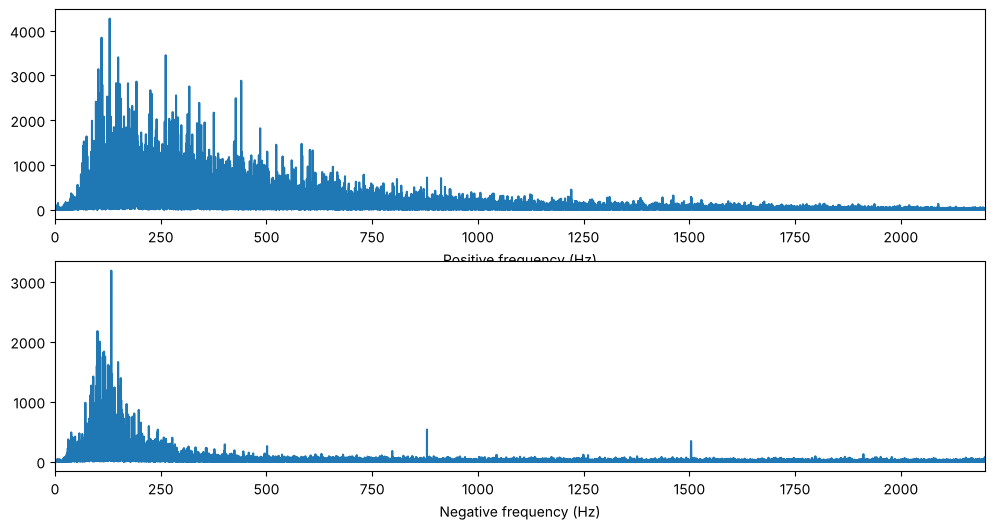

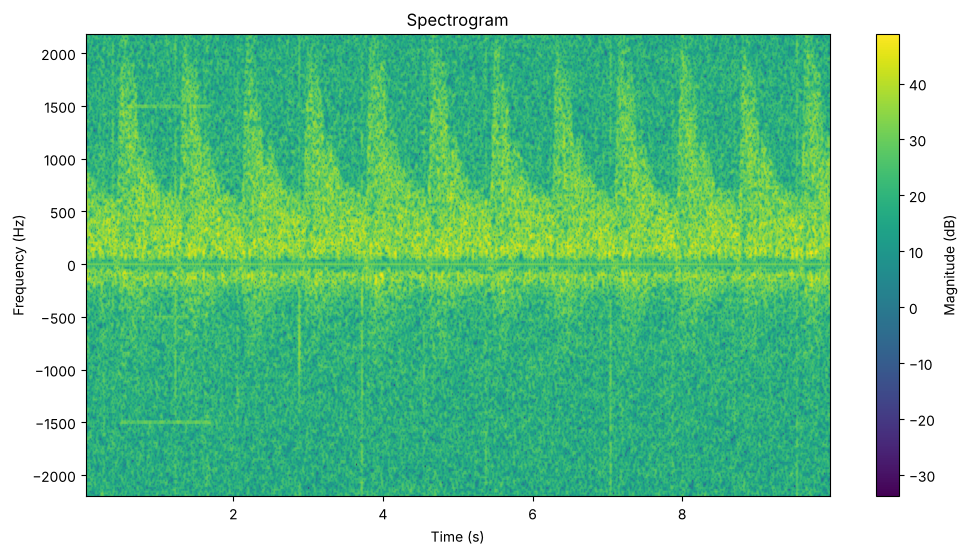

In [3]:
Xspec = np.fft.fft(x - np.mean(x)) / len(x)
Xspec_fp = np.abs(Xspec[:len(Xspec) // 2]) ** 2
fp = np.linspace(0, Fs / 2, len(Xspec_fp))

Xspec_fn = np.flipud(np.abs(Xspec[len(Xspec) // 2 + 1:]) ** 2)
fn = np.linspace(0, Fs / 2, len(Xspec_fn))

plt.figure()
plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)
plt.plot(fp, Xspec_fp)
plt.xlabel('Positive frequency (Hz)')
plt.xlim([0, Fs / 2])

plt.subplot(2, 1, 2)
plt.plot(fn, Xspec_fn)
plt.xlabel('Negative frequency (Hz)')
plt.xlim([0, Fs / 2])

plt.show()

# Plot the spectrogram
plt.figure(figsize=(12, 6))
plt.specgram(x, NFFT=256, Fs=Fs, window=kaiser(256, 5), noverlap=220)
plt.ylabel('Frequency (Hz)')
plt.xlabel('Time (s)')
plt.colorbar(label='Magnitude (dB)')
plt.title('Spectrogram')
plt.show()



## 3. Short-time energy

The segment is cut into overlapping frames (64 samples, 80 % overlap). For each frame, the energy is computed from the Hamming-weighted 512-point FFT magnitude, giving one energy value per frame.

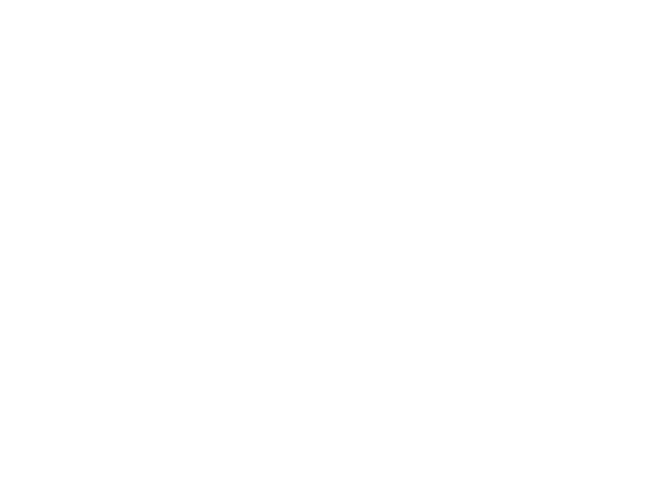

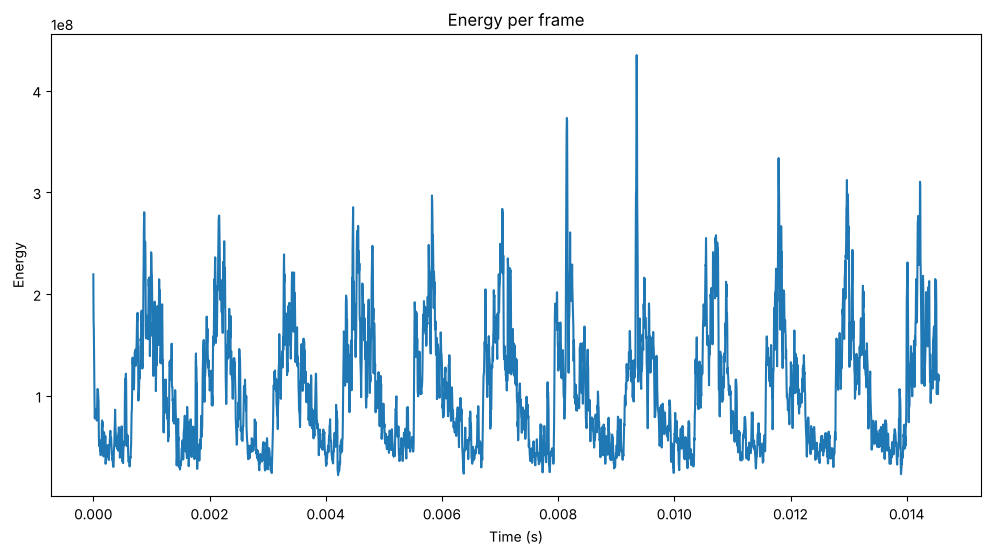

In [4]:
frame_duration = Lwind / Fs

l = 1
Energy = []
while (l - 1) * Delay + Lwind < NObs:
    x_wind = x[(l - 1) * Delay:l * Delay + Lwind]
    S = np.abs(np.fft.fft(x_wind, 512))
    FrpPos = np.arange(len(S) // 2)
    FrqNeg = np.arange(len(S) // 2, len(S))
    Energy.append([
        np.sum((S[FrpPos] * hamming(len(FrpPos))) ** 2) / len(FrpPos),
        #np.sum((S[FrqNeg] * hamming(len(FrqNeg))) ** 2) / len(FrqNeg)
    ])
    l += 1

Energy = np.array(Energy)
Sgl = Energy[:, 0]
tx = np.linspace(0, frame_duration, len(Sgl))

plt.figure()
plt.figure(figsize=(12, 6))
plt.plot(tx, Sgl)
plt.xlabel('Time (s)')
plt.ylabel('Energy')
plt.title('Energy per frame')
plt.show()


## 4. Background estimation

The time axis is rebuilt from the frame step. A low-pass Butterworth filter smooths the per-frame energy to estimate the slow background. Subtracting it leaves the noise and the transient peaks (`noise_and_peaks`).

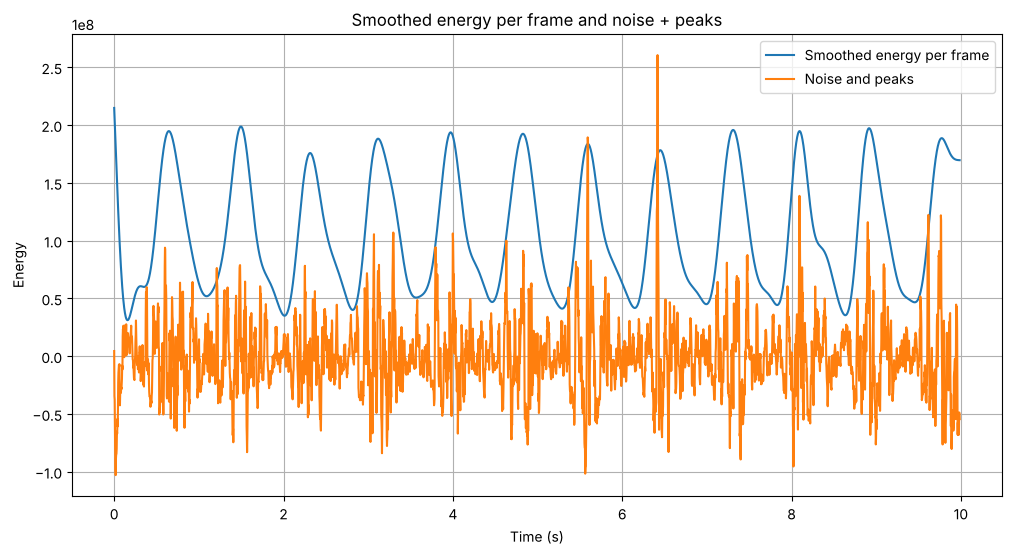

In [5]:
# Correct the time axis for the last plot
epoch_times = np.arange(len(Sgl)) * (Delay / Fs)

# Low-pass filter parameters
order = 6  # Filter order
cutoff_freq = 0.01  # Filter cut-off frequency (Hz)

# Design the low-pass filter
b, a = butter(order, cutoff_freq, fs=1)

# Low-pass filter the per-frame energy to estimate the background
smoothed_energy = filtfilt(b, a, Sgl)

# Subtract the smoothed energy from the original energy
noise_and_peaks = Sgl - smoothed_energy

plt.figure(figsize=(12, 6))
# Plot the points above the smoothed trace
plt.plot(epoch_times, smoothed_energy, label='Smoothed energy per frame')
plt.plot(epoch_times, noise_and_peaks, label='Noise and peaks')
plt.xlabel('Time (s)')
plt.ylabel('Energy')
plt.title('Smoothed energy per frame and noise + peaks')
plt.legend()
plt.grid(True)
plt.show()

## 5. Outlier removal (optional)

`remove_outliers` suppresses the largest peaks so that the remaining noise can be characterised.

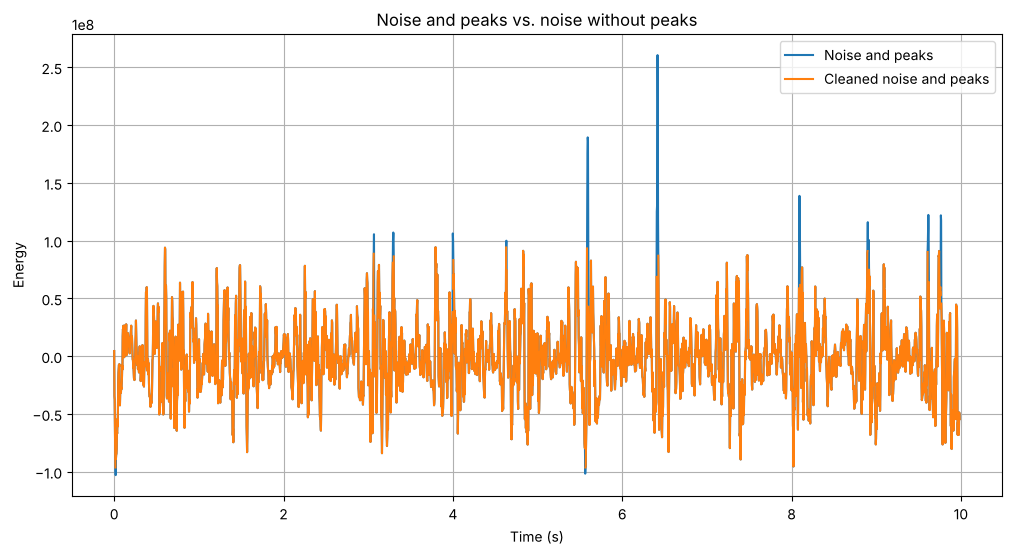

In [6]:
# Outlier removal (equivalent of MATLAB's rmoutliers)
def remove_outliers(signal, threshold=3):
    mean_signal = np.mean(signal)
    std_signal = np.std(signal)
    outlier_indices = np.abs(signal - mean_signal) > threshold * std_signal
    clean_signal = signal.copy()
    clean_signal[outlier_indices] = np.nan
    return clean_signal

# Apply remove_outliers to the noise-and-peaks signal
clean_noise_and_peaks = remove_outliers(noise_and_peaks)

# Subtract the smoothed energy to obtain the noise without peaks
clean_noise = noise_and_peaks - smoothed_energy

# Plot the signals
plt.figure(figsize=(12, 6))

plt.plot(epoch_times, noise_and_peaks, label='Noise and peaks')
plt.plot(epoch_times, clean_noise_and_peaks, label='Cleaned noise and peaks')

plt.xlabel('Time (s)')
plt.ylabel('Energy')
plt.title('Noise and peaks vs. noise without peaks')
plt.legend()
plt.grid(True)
plt.show()


## 6. Detection with a fixed threshold

First approach: peaks of `noise_and_peaks` above a fixed height are marked as candidate events and counted.

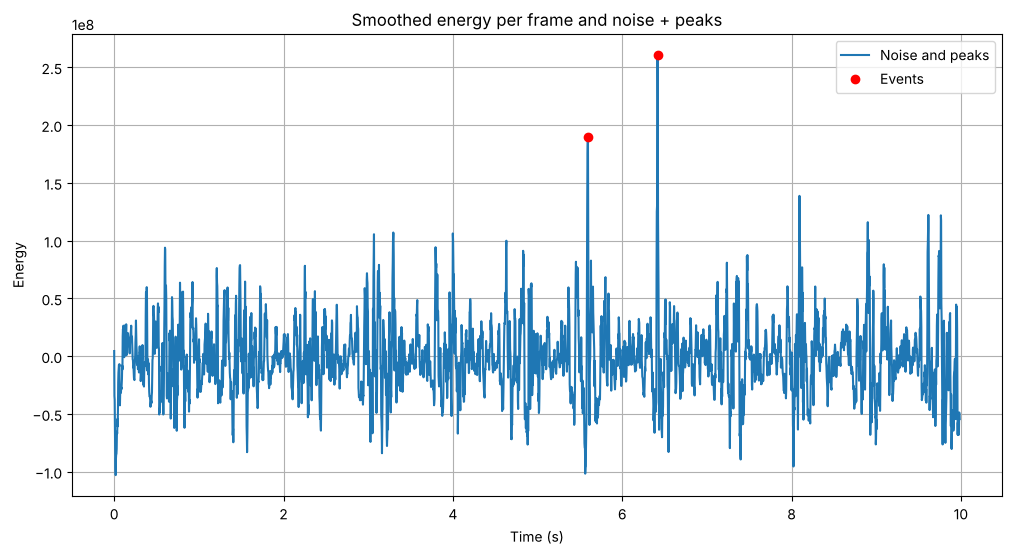

Number of events: 2


In [7]:
fixed_threshold = 1.5e8
peaks, _ = find_peaks(noise_and_peaks, height=fixed_threshold)
n_events_fixed = len(peaks)

# Plot the detected events
plt.figure(figsize=(12, 6))
plt.plot(epoch_times, noise_and_peaks, label='Noise and peaks')
plt.plot(epoch_times[peaks], noise_and_peaks[peaks], 'ro', label='Events')
plt.xlabel('Time (s)')
plt.ylabel('Energy')
plt.title('Smoothed energy per frame and noise + peaks')
plt.legend()
plt.grid(True)
plt.show()

# Print the number of events
print("Number of events:", n_events_fixed)

## 7. Negative envelope

Local minima of the signal (peaks of the inverted signal) are extracted and interpolated to give a smooth negative envelope.

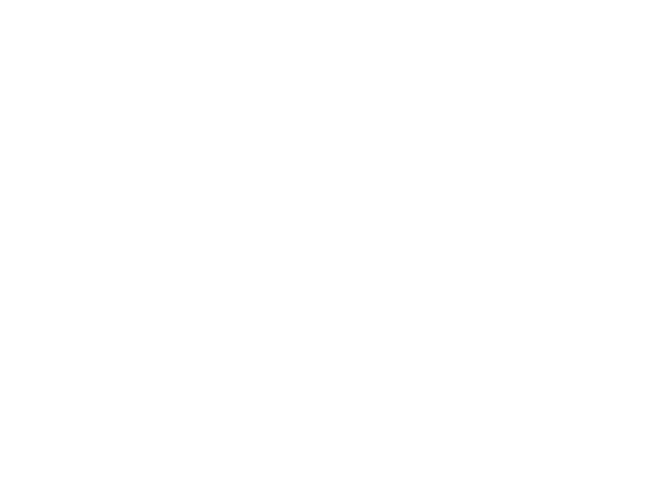

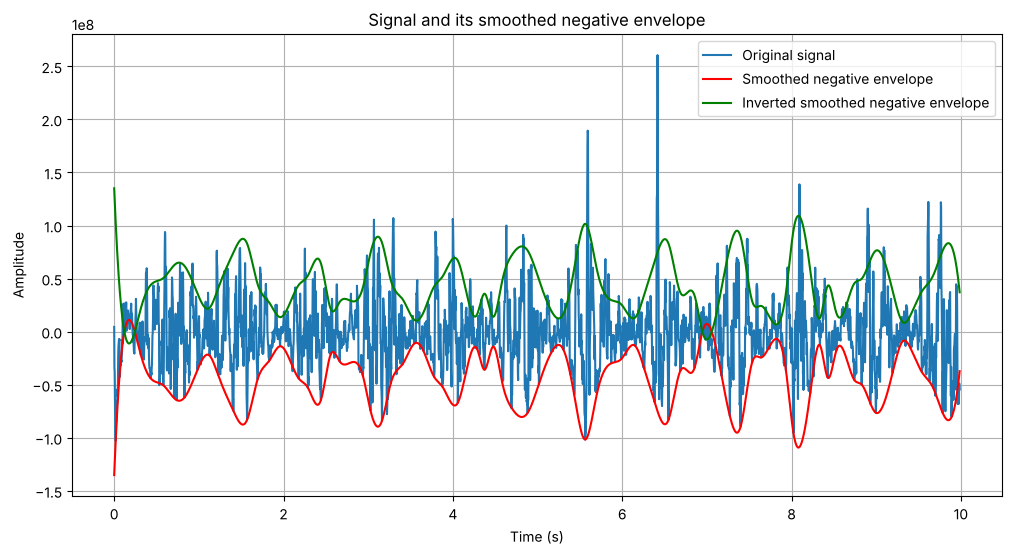

In [8]:
# Local minima defining the negative envelope
min_peaks, _ = find_peaks(-noise_and_peaks.real, distance=30, width=4, prominence=2)  # Find the peaks of the inverted signal

# Extract the minimum values and their indices
negative_envelope = noise_and_peaks.real[min_peaks]
tx_negative_envelope = tx[min_peaks]

# Interpolate to obtain a smooth envelope
interp_func = interp1d(tx_negative_envelope, negative_envelope, kind='cubic', fill_value="extrapolate")
final=smooth_negative_envelope = interp_func(tx)

# Plot the smoothed negative envelope
plt.figure()
plt.figure(figsize=(12, 6))
plt.plot(epoch_times, noise_and_peaks.real, label='Original signal')
plt.plot(epoch_times, smooth_negative_envelope, 'r', label='Smoothed negative envelope')
plt.plot(epoch_times, -smooth_negative_envelope, 'g', label='Inverted smoothed negative envelope')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title('Signal and its smoothed negative envelope')
plt.legend()
plt.grid(True)
plt.show()


## 8. Detection from the distance to the envelope

Points that lie far enough from the smoothed negative envelope are flagged as peaks, and their mean distance to the envelope is computed.

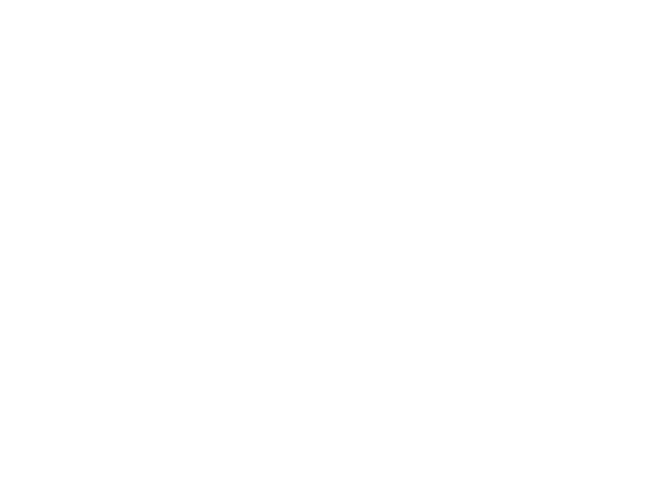

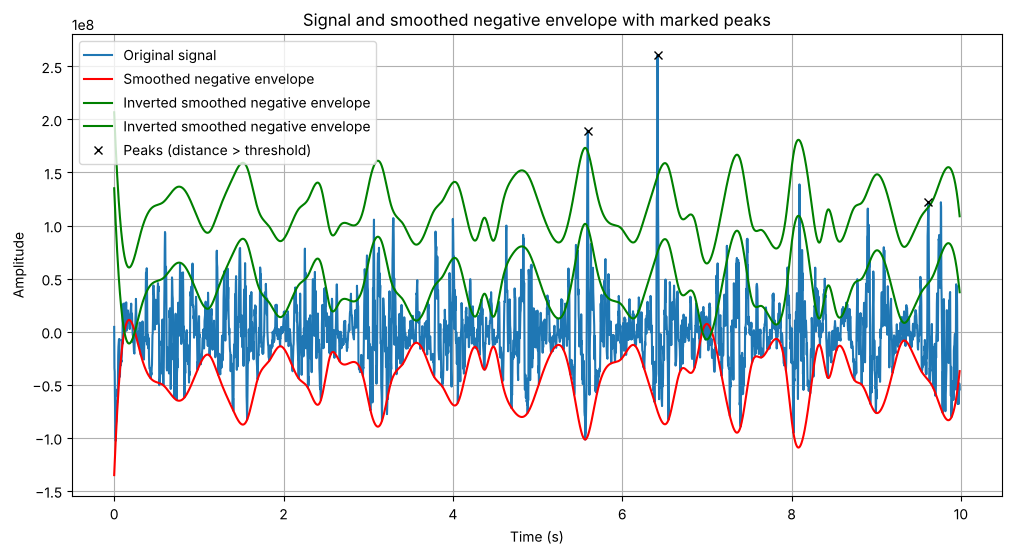

In [9]:
# Distance between noise_and_peaks and the smoothed negative envelope
distance = noise_and_peaks.real - smooth_negative_envelope

# Indices where the distance exceeds the threshold
peaks, properties = find_peaks(distance, height=-smooth_negative_envelope)

# Distances between the detected peaks and the smoothed negative envelope
peak_envelope_distances = np.abs(distance[peaks])

# Mean distance
fixed_threshold = np.mean(peak_envelope_distances)

# Distance between noise_and_peaks and the smoothed negative envelope
distance = noise_and_peaks.real + smooth_negative_envelope

# Indices where the distance exceeds the threshold
peaks, _ = find_peaks(distance, height=fixed_threshold)

# Plot the signal, the smoothed negative envelope and the peaks
plt.figure()
plt.figure(figsize=(12, 6))
plt.plot(epoch_times, noise_and_peaks.real, label='Original signal')
plt.plot(epoch_times, smooth_negative_envelope, 'r', label='Smoothed negative envelope')
plt.plot(epoch_times, -smooth_negative_envelope, 'g', label='Inverted smoothed negative envelope')
plt.plot(epoch_times, -smooth_negative_envelope+fixed_threshold, 'g', label='Inverted smoothed negative envelope')

# Add the peaks to the plot
plt.plot(epoch_times[peaks], noise_and_peaks.real[peaks], 'kx', label='Peaks (distance > threshold)')

plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title('Signal and smoothed negative envelope with marked peaks')
plt.legend()
plt.grid(True)
plt.show()

## 9. Repeated detection with added noise

The detection is repeated 200 times with random Gaussian noise added to the input (fixed seed for reproducibility). Neighbouring detections are merged, and a position is kept as an event if it is detected in enough iterations.

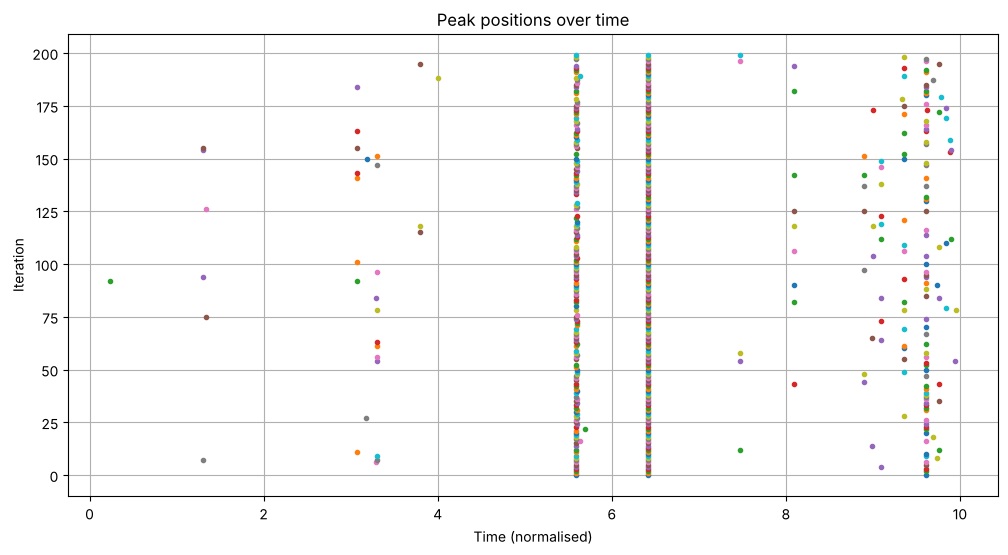

Number of events: 2
Event positions: [5.503865393360619, 6.352205547976354]


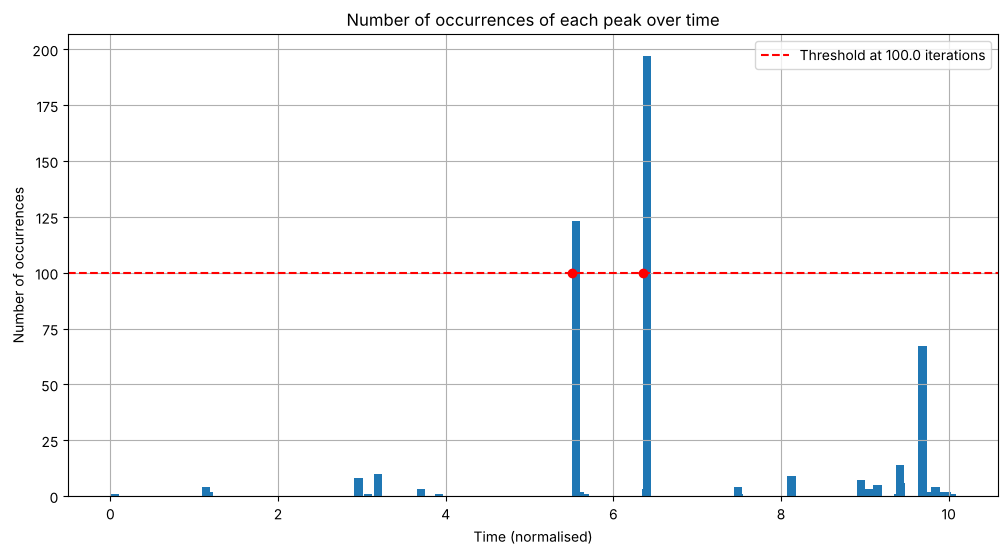

In [10]:
np.random.seed(0)  # fixed seed for reproducibility
# Peak positions of each iteration
iteration_peak_positions = []

iteration = 200 # Number of iterations

# Merge neighbouring peaks
def merge_close_peaks(peaks, distance_threshold):
    if len(peaks) == 0:
        return peaks
    merged_peaks = [peaks[0]]
    for peak in peaks[1:]:
        if peak - merged_peaks[-1] <= distance_threshold:
            merged_peaks[-1] = (merged_peaks[-1] + peak) // 2
        else:
            merged_peaks.append(peak)
    return np.array(merged_peaks)

for _ in range(iteration):  # Loop over 200 iterations
    # Add random Gaussian noise to x
    noise_level = np.std(np.real(x)) * 0.35  # Noise level
    random_noise = np.random.normal(0, noise_level, len(x))
    v = x + random_noise
    
    Xspec = np.fft.fft(v - np.mean(v)) / len(x)
    Xspec_fp = np.abs(Xspec[:len(Xspec) // 2]) ** 2
    fp = np.linspace(0, Fs / 2, len(Xspec_fp))

    Xspec_fn = np.flipud(np.abs(Xspec[len(Xspec) // 2 + 1:]) ** 2)
    fn = np.linspace(0, Fs / 2, len(Xspec_fn))

    frame_duration = Lwind / Fs

    l = 1
    Energy = []
    while (l - 1) * Delay + Lwind < NObs:
        x_wind = v[(l - 1) * Delay:l * Delay + Lwind]
        S = np.abs(np.fft.fft(x_wind, 512))
        FrpPos = np.arange(len(S) // 2)
        FrqNeg = np.arange(len(S) // 2, len(S))
        Energy.append([
            np.sum((S[FrpPos] * hamming(len(FrpPos))) ** 2) / len(FrpPos),
        ])
        l += 1

    Energy = np.array(Energy)
    Sgl = Energy[:, 0]
    tx = np.linspace(0, frame_duration, len(Sgl))

    order = 6  # Filter order
    cutoff_freq = 0.01  # Filter cut-off frequency (Hz)

    # Design the low-pass filter
    b, a = butter(order, cutoff_freq, fs=1)

    # Low-pass filter the per-frame energy to estimate the background
    smoothed_energy = filtfilt(b, a, Sgl)

    # Subtract the smoothed energy from the original energy
    noise_and_peaks = Sgl - smoothed_energy
    
    def remove_outliers(signal, threshold=3):
        mean_signal = np.mean(signal)
        std_signal = np.std(signal)
        outlier_indices = np.abs(signal - mean_signal) > threshold * std_signal
        clean_signal = signal.copy()
        clean_signal[outlier_indices] = np.nan
        return clean_signal

    # Apply remove_outliers to the noise-and-peaks signal
    clean_noise_and_peaks = remove_outliers(noise_and_peaks)

    # Subtract the smoothed energy to obtain the noise without peaks
    clean_noise = noise_and_peaks - smoothed_energy

    event_indices = np.where(clean_noise_and_peaks > noise_and_peaks)[0]
    n_events_fixed = len(event_indices)

    # Local minima defining the negative envelope
    min_peaks, _ = find_peaks(-noise_and_peaks.real, distance=20, width=5)

    # Extract the minimum values and their indices
    negative_envelope = noise_and_peaks.real[min_peaks]
    tx_negative_envelope = tx[min_peaks]

    # Interpolate to obtain a smooth envelope
    interp_func = interp1d(tx_negative_envelope, negative_envelope, kind='cubic', fill_value="extrapolate")
    smooth_negative_envelope = interp_func(tx)
    
    # Distance between noise_and_peaks and the smoothed negative envelope
    distance = noise_and_peaks.real - smooth_negative_envelope

    # Indices where the distance exceeds the threshold
    peaks, properties = find_peaks(distance, height=-smooth_negative_envelope)

    # Distances between the detected peaks and the smoothed negative envelope
    peak_envelope_distances = np.abs(distance[peaks])

    # Mean distance
    fixed_threshold = np.mean(peak_envelope_distances)

    # Distance between noise_and_peaks and the smoothed negative envelope
    distance = noise_and_peaks.real + smooth_negative_envelope

    # Indices where the distance exceeds the threshold
    peaks, _ = find_peaks(distance, height=fixed_threshold)

    # Merge neighbouring peaks
    distance_threshold = 200  # Maximum index distance for merging peaks
    merged_peaks = merge_close_peaks(peaks, distance_threshold)
    
    # Record the peak positions
    iteration_peak_positions.append(merged_peaks)

# Count how many times each peak position appeared
position_counts, bin_edges = np.histogram(np.concatenate(iteration_peak_positions), bins=len(tx))

# Initialise the event counter
n_events = 0
event_positions = []

plt.figure(figsize=(12, 6))
for i, positions in enumerate(iteration_peak_positions):
    plt.plot(epoch_times[positions], [i] * len(positions), '.')
plt.xlabel('Time (normalised)')
plt.ylabel('Iteration')
plt.title('Peak positions over time')
plt.grid(True)
plt.show()

# Iteration-count threshold
iteration_threshold = iteration/2

# Keep the peak positions whose count exceeds the threshold
for i, count in enumerate(position_counts):
    if count > iteration_threshold:
        n_events += 1
        event_positions.append(epoch_times[i])

print(f"Number of events: {n_events}")
print(f"Event positions: {event_positions}")

# Plot the peak positions against the number of times each peak appeared
plt.figure(figsize=(12, 6))
plt.bar(epoch_times, position_counts, width=0.1, align='edge')

# Horizontal line at the threshold (iteration count)
plt.axhline(y=iteration_threshold, color='red', linestyle='--', label=f'Threshold at {iteration_threshold} iterations')

# Mark the bars exceeding the threshold with small circles
for event_pos in event_positions:
    plt.plot(event_pos, iteration_threshold, 'ro')

plt.xlabel('Time (normalised)')
plt.ylabel('Number of occurrences')
plt.title('Number of occurrences of each peak over time')
plt.legend()
plt.grid(True)
plt.show()


## 10. Artefact detection

Doppler signals are also affected by artefacts, for example patient motion or fluctuations caused by moving red blood cells. Artefacts are searched for in the negative-frequency part of the signal: the per-frame energy and its background are computed as above, for negative frequencies.

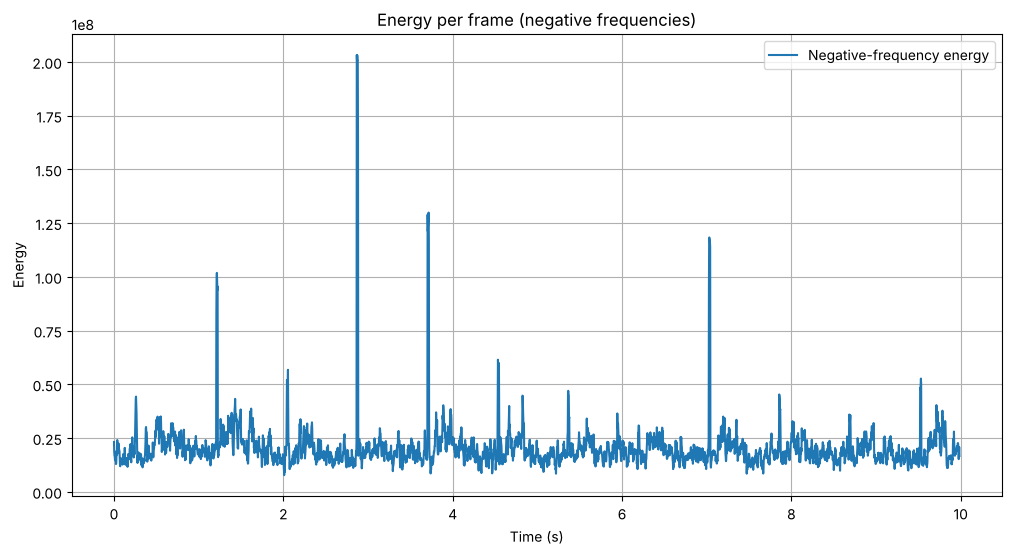

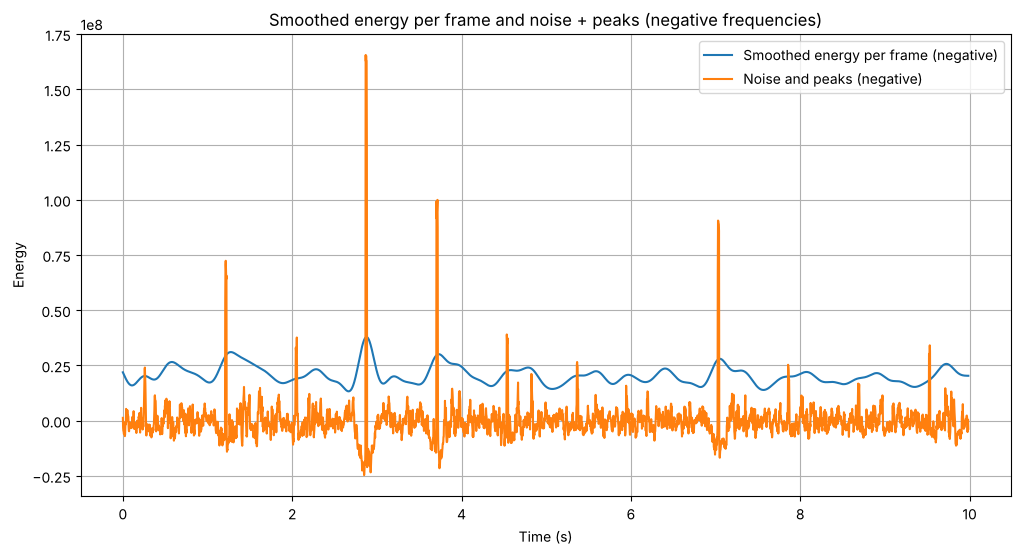

In [11]:
filename = '../data/T54_a.wav'
Fs, y = wav.read(filename)
X = y[:, 0] - 1j * y[:, 1]
Nmax = len(X)
TotalDuration = Nmax / Fs

Overlap = 80 / 100
Lwind = 64
Delay = round(Lwind - (Lwind * Overlap))
ED = 10  # Frame duration
NObs = int(ED * Fs)
k = 1 # Segment index: 1 = [0, 10] s, 2 = [10, 20] s, etc.
x = X[(k - 1) * NObs:k * NObs]
tx = np.linspace(0, ED, len(x))

Xspec = np.fft.fft(x - np.mean(x)) / len(x)
Xspec_fp = np.abs(Xspec[:len(Xspec) // 2]) ** 2
fp = np.linspace(0, Fs / 2, len(Xspec_fp))

Xspec_fn = np.flipud(np.abs(Xspec[len(Xspec) // 2 + 1:]) ** 2)
fn = np.linspace(0, Fs / 2, len(Xspec_fn))

# Per-frame energy for positive and negative frequencies
frame_duration = Lwind / Fs
l = 1
Energy_neg = []
Energy_pos = []

while (l - 1) * Delay + Lwind < NObs:
    x_wind = x[(l - 1) * Delay:l * Delay + Lwind]
    S = np.abs(np.fft.fft(x_wind, 512))
    FrpPos = np.arange(len(S) // 2)
    FrqNeg = np.arange(len(S) // 2, len(S))
    Energy_pos.append(np.sum((S[FrpPos] * hamming(len(FrpPos))) ** 2) / len(FrpPos))
    Energy_neg.append(np.sum((S[FrqNeg] * hamming(len(FrqNeg))) ** 2) / len(FrqNeg))
    l += 1

Energy_pos = np.array(Energy_pos)
Energy_neg = np.array(Energy_neg)

# Correct the time axis
epoch_times = np.arange(len(Energy_pos)) * (Delay / Fs)

# Plot the per-frame energy for negative frequencies
plt.figure(figsize=(12, 6))
plt.plot(epoch_times, Energy_neg, label='Negative-frequency energy')
plt.xlabel('Time (s)')
plt.ylabel('Energy')
plt.title('Energy per frame (negative frequencies)')
plt.legend()
plt.grid(True)
plt.show()

# Low-pass filter parameters
order = 6  # Filter order
cutoff_freq = 0.01  # Filter cut-off frequency (Hz)

# Design the low-pass filter
b, a = butter(order, cutoff_freq, fs=1)

# Low-pass filter the per-frame energy (negative frequencies)
smoothed_energy_neg = filtfilt(b, a, Energy_neg)
noise_and_peaks_neg = Energy_neg - smoothed_energy_neg

# Plot the points above the smoothed trace (negative frequencies)
plt.figure(figsize=(12, 6))
plt.plot(epoch_times, smoothed_energy_neg, label='Smoothed energy per frame (negative)')
plt.plot(epoch_times, noise_and_peaks_neg, label='Noise and peaks (negative)')
plt.xlabel('Time (s)')
plt.ylabel('Energy')
plt.title('Smoothed energy per frame and noise + peaks (negative frequencies)')
plt.legend()
plt.grid(True)
plt.show()

## 11. Percentile-based peak detection

In the negative-frequency noise-and-peaks signal, points above the 99th percentile are flagged as artefact peaks.

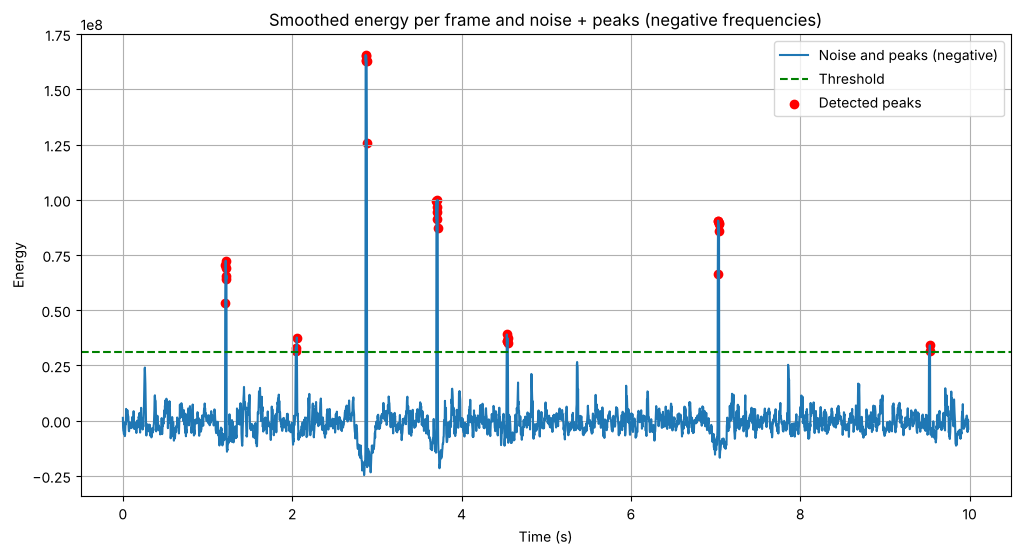

Detected peak positions: [1.20895862 1.21191451 1.2148704  1.21782628 1.22078217 1.22373806
 2.04251933 2.04547522 2.05434288 2.86721237 2.87016826 2.87312415
 2.87608004 2.87903593 2.88199181 3.70372897 3.70668486 3.70964075
 3.71259663 3.71555252 3.71850841 4.53433379 4.53728968 4.54024557
 4.54320146 4.54615734 7.02614825 7.02910414 7.03206003 7.03501592
 7.03797181 7.04092769 9.52978627 9.53274216]


In [12]:
# Detect peaks in noise_and_peaks_neg using the 99th percentile
threshold = np.percentile(noise_and_peaks_neg, 99)
peaks_indices = np.where(noise_and_peaks_neg > threshold)[0]

# Plot the points above the smoothed trace (negative frequencies)
plt.figure(figsize=(12, 6))
plt.plot(epoch_times, noise_and_peaks_neg, label='Noise and peaks (negative)')
plt.axhline(y=threshold, color='green', linestyle='--', label='Threshold')  # Add the threshold line
plt.scatter(epoch_times[peaks_indices], noise_and_peaks_neg[peaks_indices], color='red', label='Detected peaks')
plt.xlabel('Time (s)')
plt.ylabel('Energy')
plt.title('Smoothed energy per frame and noise + peaks (negative frequencies)')
plt.legend()
plt.grid(True)
plt.show()

# Store the detected peak positions
peaks_positions_neg = epoch_times[peaks_indices]
print("Detected peak positions:", peaks_positions_neg)

## 12. Selection of relevant peaks

Artefact peaks are kept only if at least 3 detected peaks fall within a short time window around them, so that isolated points are ignored.

In [13]:
# Sort the detected peak positions
sorted_peaks_positions_neg = np.sort(peaks_positions_neg)

# Time window around each peak
window_size = 0.1

# Peaks to keep
selected_peaks = []

# Loop over the peak positions
for i, peak_pos in enumerate(sorted_peaks_positions_neg):
    # Count the peaks inside the time window around peak_pos
    num_peaks_in_window = np.sum(np.abs(sorted_peaks_positions_neg - peak_pos) < window_size)
    # Keep the peak if its window contains at least 3 peaks
    if num_peaks_in_window >= 3:
        selected_peaks.append(peak_pos)

# Plot the selected peaks
print("Selected peaks:", selected_peaks)

Selected peaks: [1.2089586175534335, 1.2119145065939063, 1.2148703956343794, 1.2178262846748522, 1.2207821737153253, 1.223738062755798, 2.0425193269668034, 2.045475216007276, 2.054342883128695, 2.867212369258754, 2.870168258299227, 2.8731241473397002, 2.876080036380173, 2.879035925420646, 2.8819918144611187, 3.703728967712597, 3.70668485675307, 3.7096407457935427, 3.7125966348340156, 3.715552523874489, 3.7185084129149617, 4.534333788085494, 4.537289677125966, 4.54024556616644, 4.543201455206913, 4.546157344247385, 7.0261482492041845, 7.029104138244657, 7.03206002728513, 7.035015916325603, 7.037971805366076, 7.040927694406549]


Per-iteration peak positions (as in section 9), shown again for comparison with the next plot.

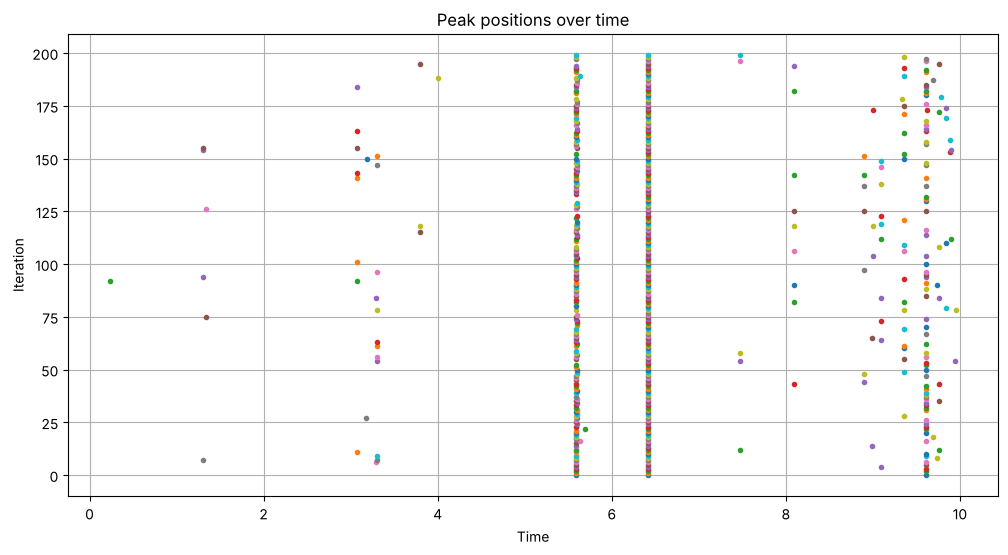

Number of events: 2
Event positions: [5.503865393360619, 6.352205547976354]


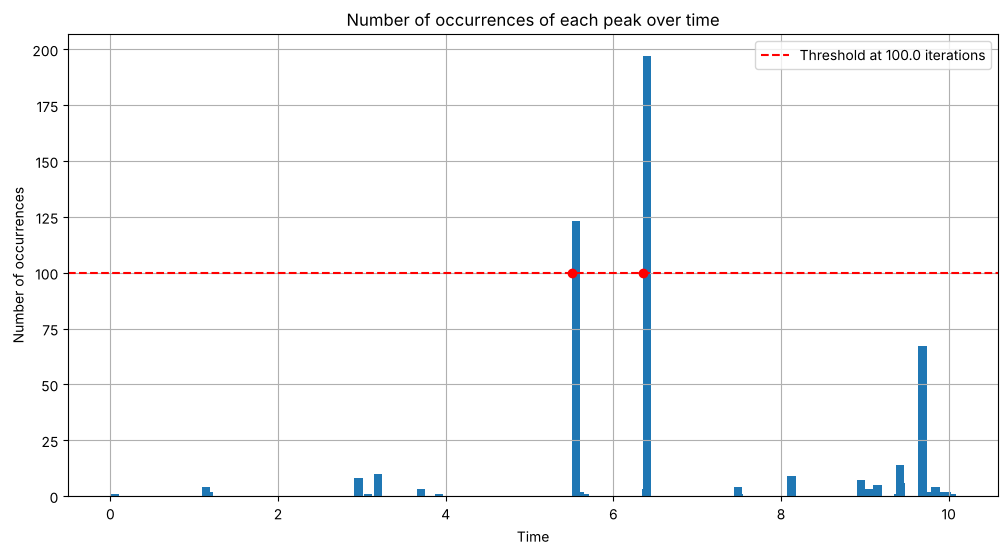

In [14]:
plt.figure(figsize=(12, 6))
for i, positions in enumerate(iteration_peak_positions):
    plt.plot(epoch_times[positions], [i] * len(positions), '.')
plt.xlabel('Time')
plt.ylabel('Iteration')
plt.title('Peak positions over time')
plt.grid(True)
plt.show()

# Iteration-count threshold
iteration_threshold = iteration/2

print(f"Number of events: {n_events}")
print(f"Event positions: {event_positions}")

# Plot the peak positions against the number of times each peak appeared
plt.figure(figsize=(12, 6))
plt.bar(epoch_times, position_counts, width=0.1, align='edge')

# Horizontal line at the threshold (iteration count)
plt.axhline(y=iteration_threshold, color='red', linestyle='--', label=f'Threshold at {iteration_threshold} iterations')

# Mark the bars exceeding the threshold with small circles
for event_pos in event_positions:
    plt.plot(event_pos, iteration_threshold, 'ro')

plt.xlabel('Time')
plt.ylabel('Number of occurrences')
plt.title('Number of occurrences of each peak over time')
plt.legend()
plt.grid(True)
plt.show()

## 13. Rejection of events that coincide with artefacts

Detected events that coincide with the selected artefact peaks are removed. The remaining event positions are printed.

In [15]:
# Remove the events that coincide with artefact peaks
event_positions = [event for event in event_positions if event not in selected_peaks]

# Print the remaining events
print("Event positions after artefact filtering:", event_positions)

Event positions after artefact filtering: [5.503865393360619, 6.352205547976354]
